# Network Interdiction Analysis

Sections, in order: flow reduction of every method per graph family, a
head-to-head table (simulated annealing + greedy repair against greedy from
scratch), a performance-distribution plot (final solution quality per
family and method), raw-annealer feasibility against problem size, a check of
this rerun against the values on the D-Wave slides, the exact penalty windows
λ with the one instance where no λ exists, and how close simulated annealing
gets to the QUBO ground state. All figures use `results/slide_instances_sa.csv`,
the classical rerun of the nine instances behind slides 8–10 of
`S-T_NIP.pptx` (the original D-Wave result files were not stored). The
D-Wave (QA) column is empty because D-Wave runs are paused.

In [1]:
from pathlib import Path
import sys
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:  # executed outside Jupyter
    display = print

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "utils.py").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import utils
utils = importlib.reload(utils)

apply_plot_style = utils.apply_plot_style
read_provenance = utils.read_provenance
load_results = utils.load_results
head_to_head_table = utils.head_to_head_table
compare_with_slides = utils.compare_with_slides
plot_ratio_by_family = utils.plot_ratio_by_family
plot_performance_distribution = utils.plot_performance_distribution
plot_raw_sa_feasibility = utils.plot_raw_sa_feasibility
plot_slide_check = utils.plot_slide_check
plot_lambda_windows = utils.plot_lambda_windows
plot_flow_curve = utils.plot_flow_curve
plot_energy_gap = utils.plot_energy_gap

apply_plot_style()

RESULTS_CSV = REPO_ROOT / "results" / "slide_instances_sa.csv"
FIGURES_DIR = REPO_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

# Instance and budget whose penalty window is empty (section "Penalty Windows").
EMPTY_WINDOW_INSTANCE = "90_0.1.erdosflow"
EMPTY_WINDOW_BUDGET = 10

df = load_results(RESULTS_CSV)

print(f"Loaded {len(df)} rows from {RESULTS_CSV.relative_to(REPO_ROOT)}")
print(f"Families: {', '.join(f'{f} ({int((df.family == f).sum())})' for f in utils.FAMILY_ORDER)}")
for line in read_provenance(RESULTS_CSV):
    print(f"  {line}")
utils_path = Path(utils.__file__).resolve().relative_to(REPO_ROOT)
print(f"Loaded utils from: {utils_path}")


%load_ext autoreload
%autoreload 2

Loaded 27 rows from results/slide_instances_sa.csv
Families: planar (9), Erdős–Rényi (9), k-NN (9)
  Generated by run_benchmark.py -- see README, "Regenerating the results CSV".
  repo commit: 7604e445edf1e4a6aab857db74e8acb490992454-dirty
  (annotated after the run: produced in a clean worktree at that commit; the '-dirty'
   flag came only from the untracked stderr capture file run.err -- no tracked file differed.)
  generated (UTC): 2026-09-30T21:41:43+00:00
  exact backend: gurobi
  solver passes: sa
  baselines: greedy, random (seed 0)
  lambda = auto: the midpoint of the exact window (lambda_lo, lambda_hi); see the run_benchmark.py docstring.
  empty lambda window (f not convex at B), baselines only: testcases/90_0.1.erdosflow B=10
  qa columns are empty: that pass was not run here. Re-run with --solvers to fill them.
Loaded utils from: utils.py


## Flow Reduction by Family

For every instance and budget B on the slides, **`plot_ratio_by_family`**
scores each method by the flow reduction it achieves as a fraction of the
optimal reduction (1.0 = optimal, computed by Gurobi):

- **SA (raw sample)** — the best budget-feasible sample among simulated
  annealing's 20 lowest-energy samples;
- **SA + greedy repair** — the best of those 20 samples after greedy repair to
  exactly B cuts;
- **Greedy from scratch** — cut the single most harmful arc, B times, starting
  from nothing;
- **Random start + repair** — 20 random starts (each arc cut with probability
  B/E) after the same repair, i.e. samples that know the budget and nothing
  else.

Lines join the budgets of one instance; the grey number under each group is
its QUBO size, the slides' x-axis label. Dark-red crosses mark rows where raw
SA had no budget-feasible sample, and "no valid λ" marks the one row whose
penalty window is empty (see **Penalty Windows** below), which therefore has
no SA result.

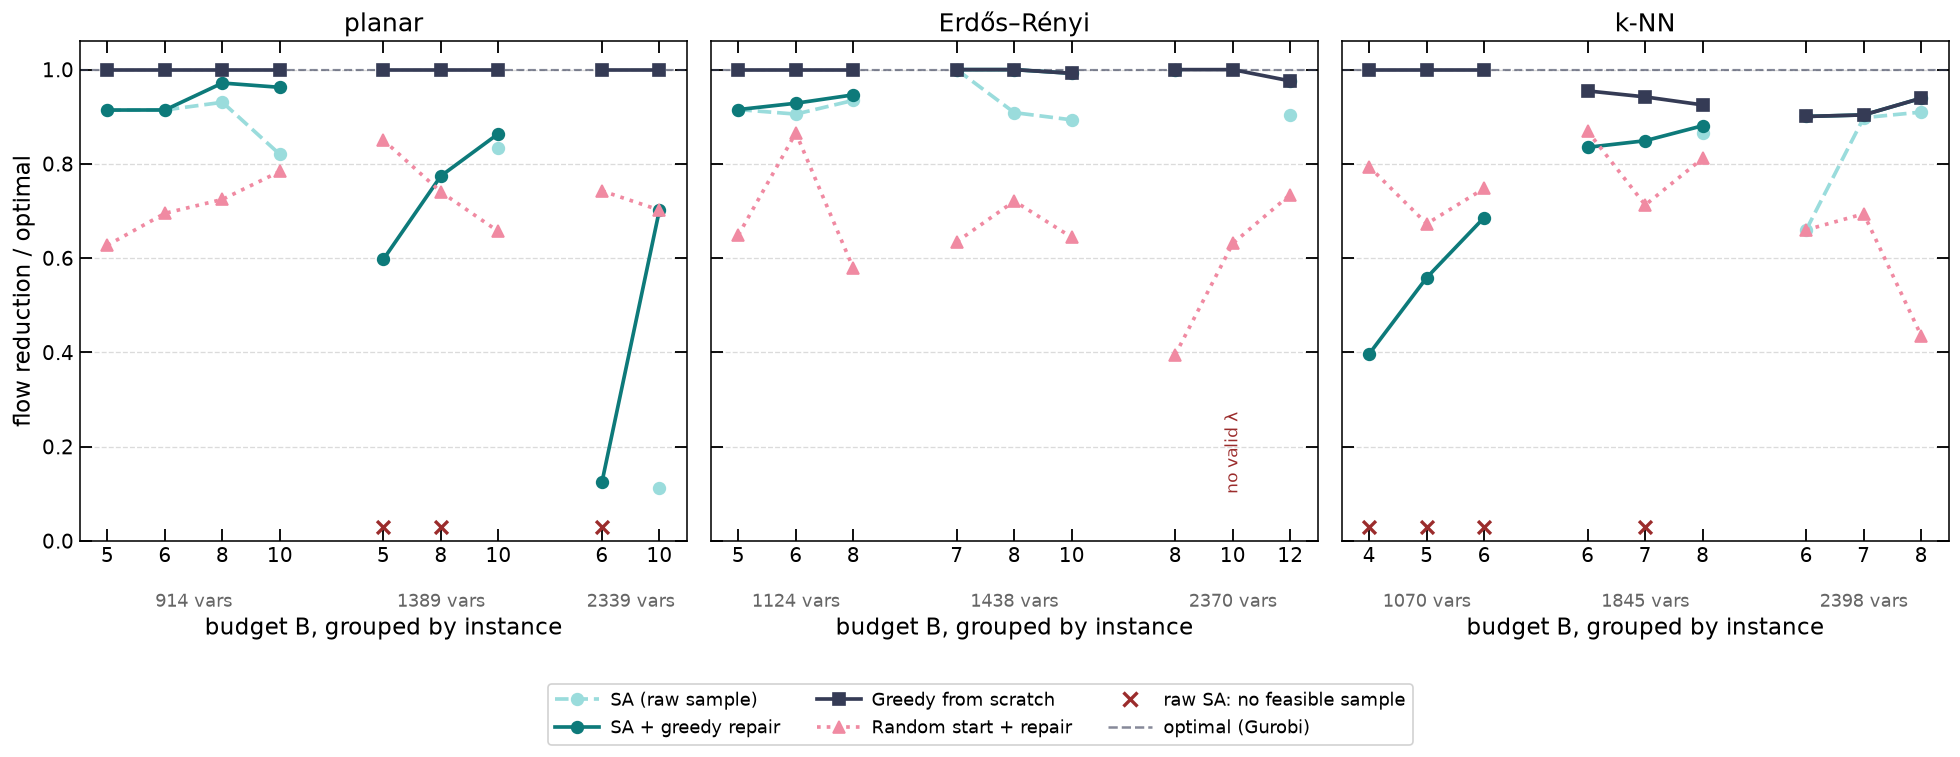

In [2]:
fig_ratio = plot_ratio_by_family(df)
plt.savefig(FIGURES_DIR / "ratio_by_family.png", dpi=150, bbox_inches="tight")
plt.show()

### Head-to-head: SA + repair against greedy from scratch

**`head_to_head_table`** counts, per family, the rows where each of the two
leaves less flow (rows without a QUBO excluded). The headline is the
`SA+repair better` column: greedy from scratch is never beaten, and it is
optimal on every planar row. The k-NN family is the only one where greedy
leaves a gap, so it is where a better method could show a benefit.

In [3]:
summary = head_to_head_table(df)
display(summary.round(3))
print(f"Greedy from scratch is optimal on {int((df['Greedy'] == df['Opt_NIP']).sum())} "
      f"of {len(df)} rows (including the empty-window row).")

,rows,SA+repair better,tie,Greedy better,Greedy optimal,SA+repair optimal,raw SA feasible,mean ratio SA+repair,mean ratio Greedy
planar,9,0,0,9,9,0,6,0.758,1.000
Erdős–Rényi,8,0,5,3,6,3,8,0.970,0.996
k-NN,9,0,3,6,3,0,5,0.772,0.952
all,26,0,8,18,18,3,19,0.828,0.982


Greedy from scratch is optimal on 19 of 27 rows (including the empty-window row).


## Performance Distribution

**`plot_performance_distribution`** reports final solution *quality* rather
than per-row detail: `performance % = 100 × ratio`, where 100% means the method
matched Gurobi's optimum. The top strip holds the rows each method solved
exactly, with the fraction above each column; the log-scale main panel shows
how far short the remaining rows fell, with a navy bar at each method's mean.
SA + repair beats random starts with the same repair in most rows — so SA's
samples do carry information about the instance — but both trail greedy from
scratch: greedy repair can add or remove cuts until there are B of them, but
it cannot swap out a wrong cut, so starting from an SA sample anchors it to
that sample's mistakes.

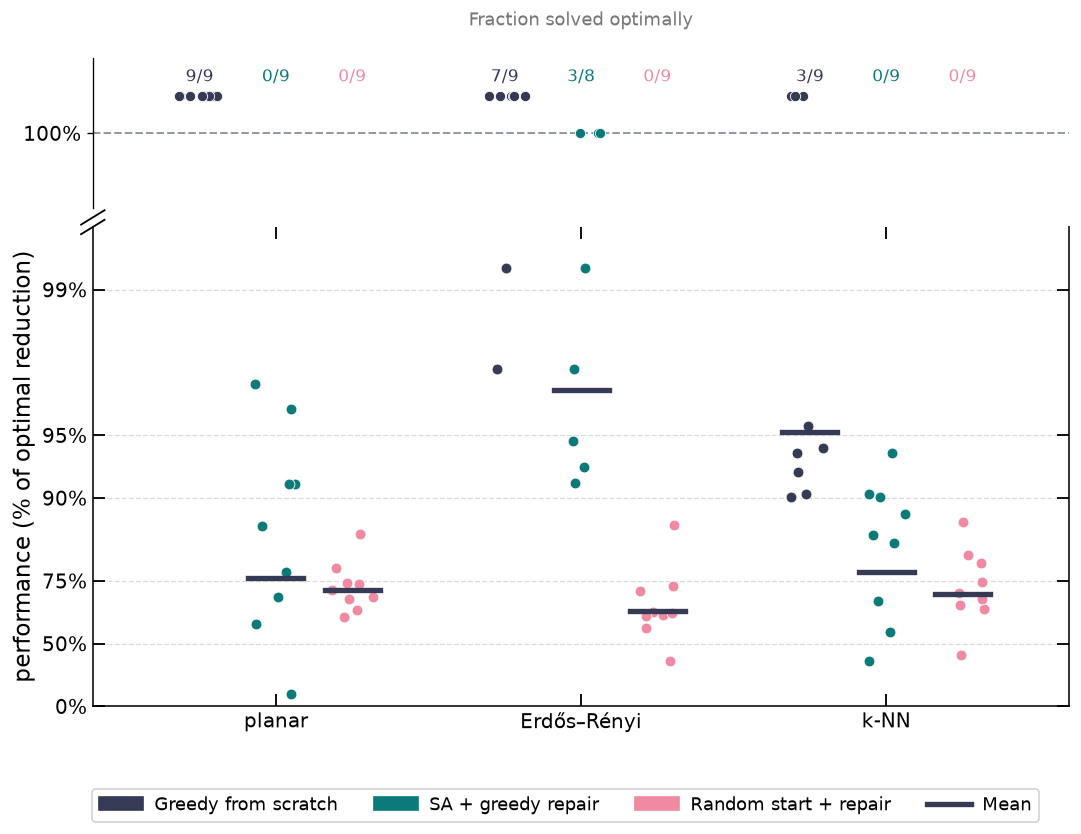

In [4]:
fig_perf = plot_performance_distribution(df)
plt.savefig(FIGURES_DIR / "performance_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Raw Annealer Feasibility vs Problem Size

The QUBO enforces the budget only through a linear penalty, so a low-energy
sample can cut more or fewer arcs than B. **`plot_raw_sa_feasibility`** shows
the quality of raw SA on rows where at least one of its 20 best samples
respected the budget; the dark-red number above a size counts the rows where
none did.

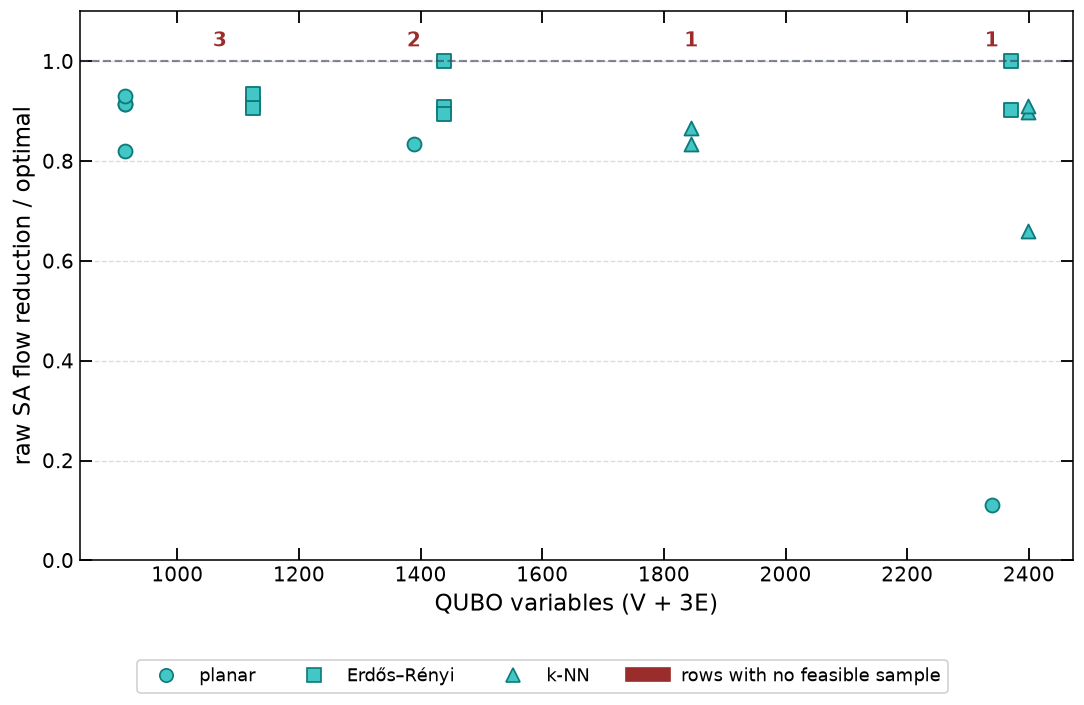

In [5]:
fig_feas = plot_raw_sa_feasibility(df)
plt.savefig(FIGURES_DIR / "raw_sa_feasibility.png", dpi=150, bbox_inches="tight")
plt.show()

## Reproducing the Slides

The slides' numbers survive only as figures, so **`compare_with_slides`**
joins this rerun with values read off slides 8–10 by eye (about ±0.01; pinned
in `utils.slide_values`). **`plot_slide_check`** puts the slides'
repaired "QA/SA-Greedy" values against this rerun's greedy from scratch
(left) and SA + repair (right). Points inside the shaded ±0.01 band agree to
reading precision.

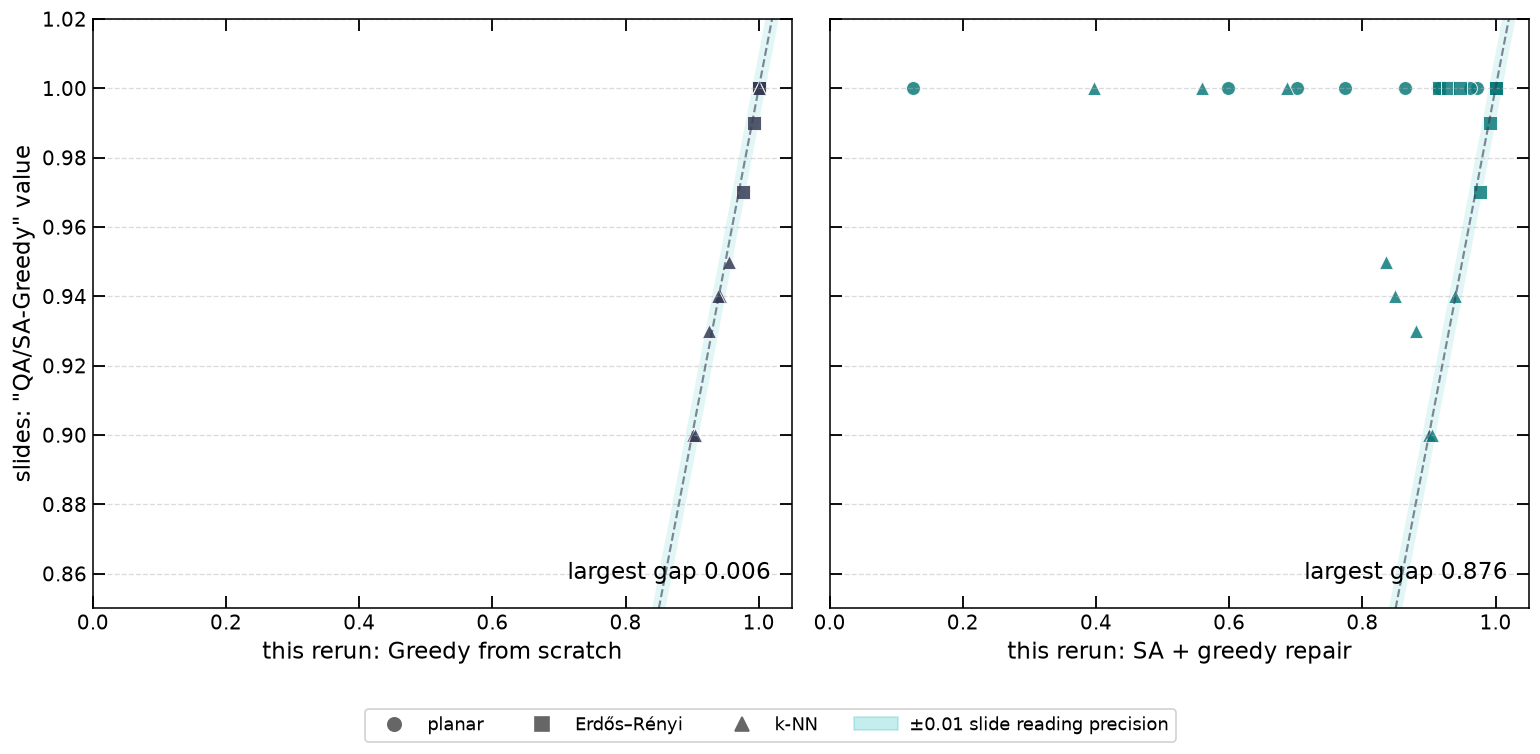

Largest gap, slides vs greedy from scratch: 0.006
Largest gap, slides vs SA + repair:         0.876
Median gap in raw SA (rows feasible in both): 0.005


In [6]:
cmp = compare_with_slides(df)
fig_slides = plot_slide_check(cmp)
plt.savefig(FIGURES_DIR / "slide_check.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Largest gap, slides vs greedy from scratch: {cmp['gap_vs_greedy'].max():.3f}")
print(f"Largest gap, slides vs SA + repair:         {cmp['gap_vs_sa_repair'].max():.3f}")
print(f"Median gap in raw SA (rows feasible in both): {cmp['gap_raw_sa'].median():.3f}")

### Why do the slides' repaired values match greedy from scratch?

Every one of the 27 repaired values on the slides lies within reading precision
of *greedy from scratch*, and far from this rerun's SA + repair. The cause is
the bug fixed in issue #12: before that fix, `improve_dwave_solution()` looked
samples up by integer index, while PyQUBO keys them `'x_0'`, `'x_1'`, …, so it
never saw a cut and always repaired from an empty solution — which *is* greedy
from scratch. It is also why the slides' QA-Greedy and SA-Greedy bars were
identical on every row. The raw QA and SA bars were real samples and are not
affected; this rerun's raw SA differs from the slides' only by sampler noise
(the median gap is printed above). The practical consequence is that the
slides' "greedy post-processing recovers optimal solutions" result describes
the greedy heuristic, not the annealer.

## Penalty Windows

The budget term in the QUBO is linear, λ·(Σx − B), so its ground state is the
optimal B-cut interdiction only for λ inside an exact window,

$$\max_{k>B}\frac{f(B)-f(k)}{k-B} \;<\; \lambda \;<\; \min_{k<B}\frac{f(k)-f(B)}{B-k},$$

where f(k) is the best surviving flow with k cuts. `run_benchmark.py`
computes the window with Gurobi and uses its midpoint.
**`plot_lambda_windows`** shows every window and the λ used. Many are only a
few units wide, which is why hand-tuned λ was fragile; one is empty.

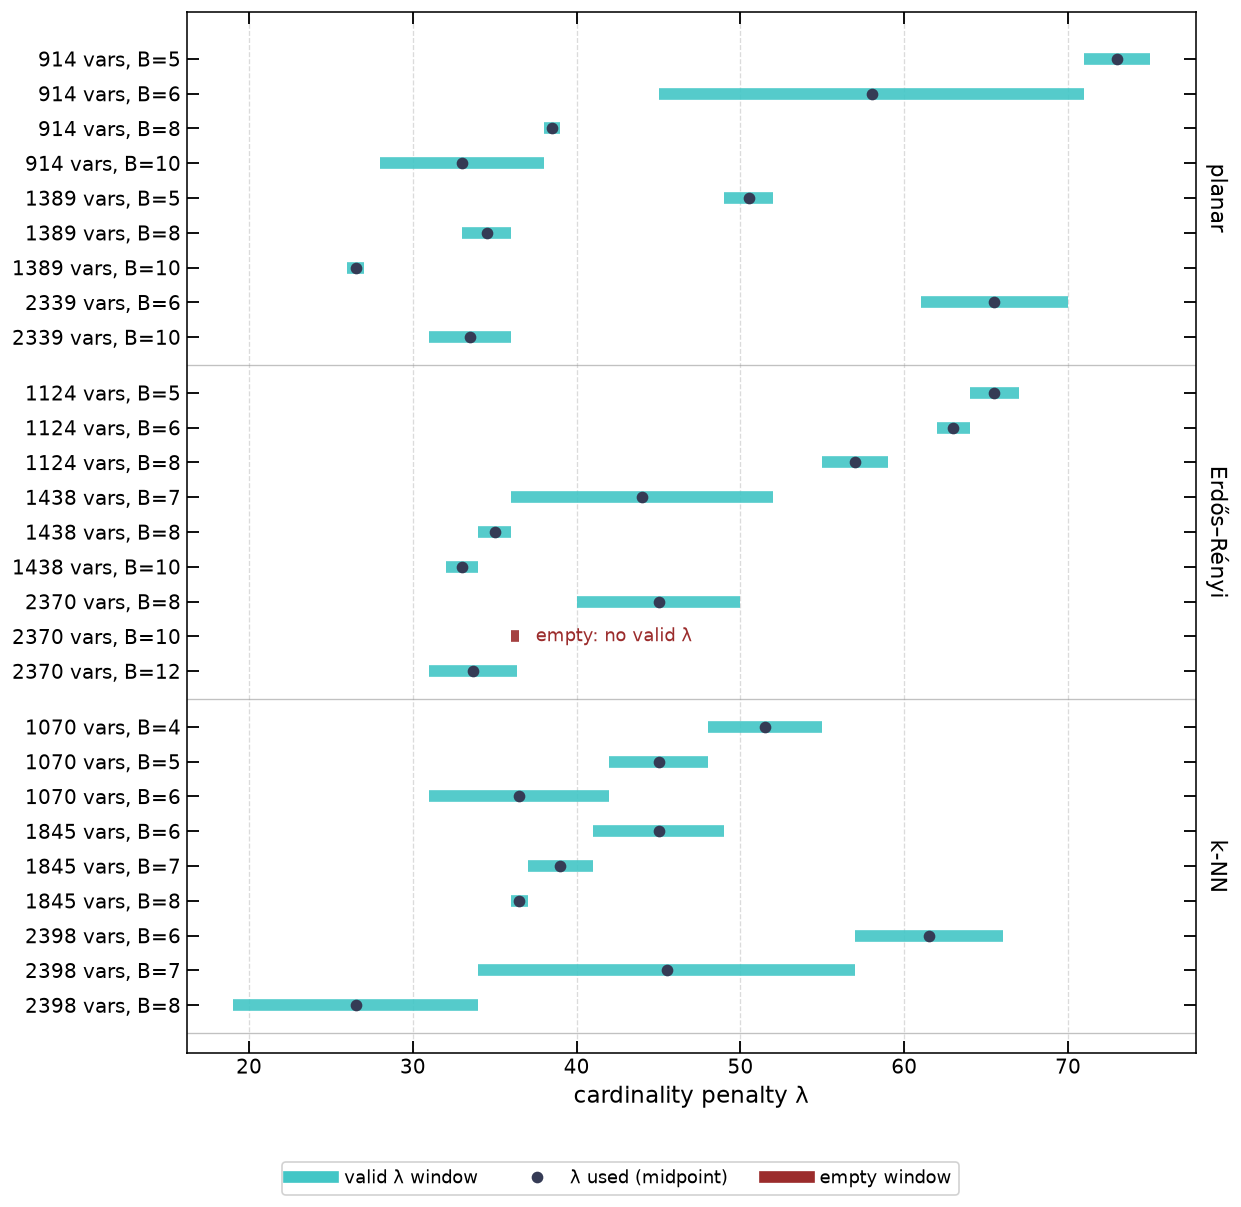

Non-empty windows: 26 of 27; median width 5.17; 6 are 2 or narrower.


In [7]:
fig_lambda = plot_lambda_windows(df)
plt.savefig(FIGURES_DIR / "lambda_windows.png", dpi=150, bbox_inches="tight")
plt.show()

nonempty = df[df["lambda_width"] > 0]
print(f"Non-empty windows: {len(nonempty)} of {len(df)}; median width "
      f"{nonempty['lambda_width'].median():.2f}; "
      f"{int((nonempty['lambda_width'] <= 2).sum())} are 2 or narrower.")

### Why is one window empty?

An empty window means f is not convex at B: the B-th cut saves less than the
average of the next few, so any per-cut price that makes the B-th cut worth
taking also makes the larger set worth taking, and the QUBO's ground state
jumps past B. **`plot_flow_curve`** draws f(k) with its lower convex envelope
for the empty-window row; the budget sits above the envelope. This cell
recomputes f with Gurobi, so it needs a full Gurobi license and is skipped
otherwise.

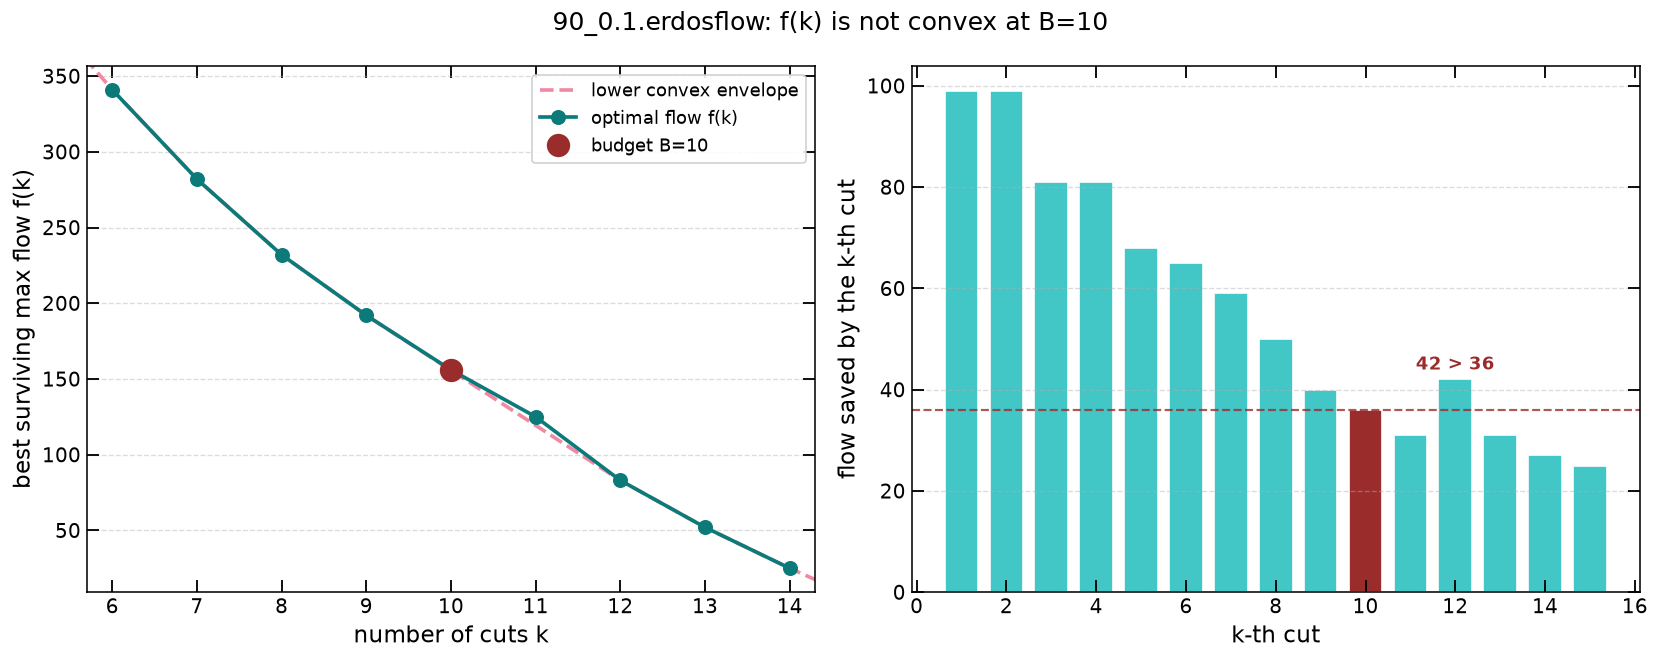

saving of the k-th cut: {8: 50, 9: 40, 10: 36, 11: 31, 12: 42, 13: 31}
window at B: (36.5, 36.0)


In [8]:
import contextlib
import io

try:
    import network_interdiction as ni
    import run_benchmark as rb

    _g, _s, _t = ni.read_flow_file(str(REPO_ROOT / "testcases" / EMPTY_WINDOW_INSTANCE))
    with contextlib.redirect_stdout(io.StringIO()):  # solve_nip_gurobi prints every solve
        flow_curve = rb.optimum_curve("gurobi", _g, _s, _t, EMPTY_WINDOW_BUDGET)
    fig_curve = plot_flow_curve(
        flow_curve, EMPTY_WINDOW_BUDGET,
        title=f"{EMPTY_WINDOW_INSTANCE}: f(k) is not convex at B={EMPTY_WINDOW_BUDGET}")
    plt.savefig(FIGURES_DIR / "flow_curve_empty_window.png", dpi=150, bbox_inches="tight")
    plt.show()
    _ks = range(EMPTY_WINDOW_BUDGET - 2, EMPTY_WINDOW_BUDGET + 4)
    print("saving of the k-th cut:",
          {k: flow_curve[k - 1] - flow_curve[k] for k in _ks})
    print("window at B:", rb.lambda_window(flow_curve, EMPTY_WINDOW_BUDGET))
except Exception as e:  # no (full) Gurobi license
    print(f"Skipped: needs a full Gurobi license ({type(e).__name__}: {e})")

## QUBO Energy Gap

**`plot_energy_gap`** measures how close simulated annealing gets to the QUBO
ground state, as the relative gap `1 − E(SA) / E(ground state)` (energies are
negative, so 0 means SA reached the ground state; those rows are counted in
dark red at the bottom).

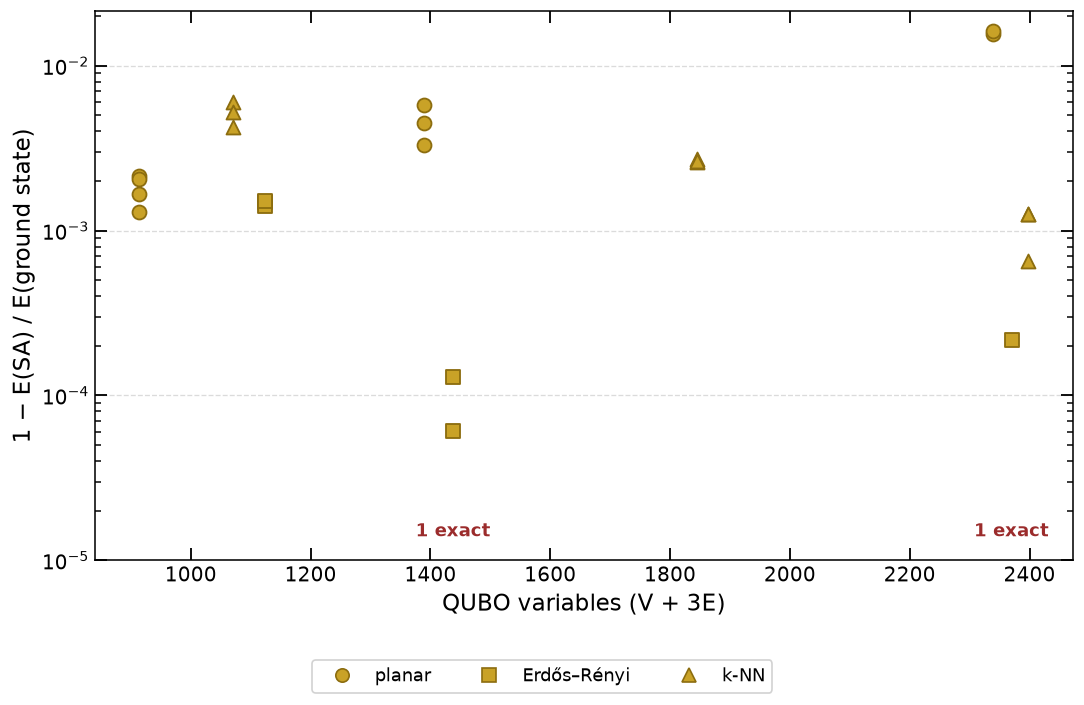

SA reached the exact ground-state energy on 2 of 26 rows.


In [9]:
fig_energy = plot_energy_gap(df)
plt.savefig(FIGURES_DIR / "energy_gap.png", dpi=150, bbox_inches="tight")
plt.show()
_e = df.dropna(subset=["SA_QUBO"])
print(f"SA reached the exact ground-state energy on "
      f"{int(np.isclose(_e['SA_QUBO'], _e['Opt_QUBO']).sum())} of {len(_e)} rows.")